In [254]:
import warnings
from pathlib import Path
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.spatial.distance import jensenshannon
from sklearn.metrics import normalized_mutual_info_score

warnings.filterwarnings("ignore", category=FutureWarning)

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 150)

sns.set_theme(style="whitegrid")

print("Libraries successfully imported.")

Libraries successfully imported.


In [255]:
# Dataset configuration
CSV_PATH = "/home/labdoo/Documents/Begin_Thesis/reference_data/EliteSportsCars_Data.csv"

# Explicit exclusions
ID_COLUMNS = ["id"]
TARGET_COLUMN = "stroke"

# For other datasets, change these to their actual column names.
# Example:
# ID_COLUMNS = ["Patient_ID"]
# TARGET_COLUMN = "Diagnosis"

DATETIME_COLUMNS = []

DOCUMENTED_MISSING_TOKENS = []

NUMERIC_BINS = 10
NMI_NUMERIC_BINS = 10
MIN_NMI_VALID_PAIRS = 3

# Load dataset
df_raw = pd.read_csv(CSV_PATH)
df = df_raw.copy()

if DOCUMENTED_MISSING_TOKENS:
    df = df.replace(DOCUMENTED_MISSING_TOKENS, np.nan)

# Exclude IDs and target
excluded_columns = set(ID_COLUMNS)

if TARGET_COLUMN is not None:
    excluded_columns.add(TARGET_COLUMN)

feature_columns = [
    col for col in df.columns
    if col not in excluded_columns
]

print("Excluded columns:", excluded_columns)
print("Features included in analysis:", feature_columns)

display(df.head())

Excluded columns: {'id', 'stroke'}
Features included in analysis: ['Brand', 'Model', 'Year', 'Country', 'Condition', 'Engine_Size', 'Horsepower', 'Torque', 'Weight', 'Top_Speed', 'Acceleration_0_100', 'Fuel_Type', 'Drivetrain', 'Transmission', 'Fuel_Efficiency', 'CO2_Emissions', 'Price', 'Mileage', 'Popularity', 'Safety_Rating', 'Number_of_Owners', 'Market_Demand', 'Insurance_Cost', 'Production_Units', 'Log_Price', 'Log_Mileage', 'Modification']


,Brand,Model,Year,Country,Condition,Engine_Size,Horsepower,Torque,Weight,Top_Speed,Acceleration_0_100,Fuel_Type,Drivetrain,Transmission,Fuel_Efficiency,CO2_Emissions,Price,Mileage,Popularity,Safety_Rating,Number_of_Owners,Market_Demand,Insurance_Cost,Production_Units,Log_Price,Log_Mileage,Modification
0,Nissan,720S,2006,Asia,used,3.7,420,705,1785,238,5.7,Diesel,RWD,Automatic,10.5,307,81580,96664,Low,2,4,Medium,13410,5000,11.309352,11.479007,V-Spec
1,McLaren,911 Turbo S,2009,Europe,new,5.3,1104,766,992,386,4.6,Electric,RWD,DCT,9.4,113,308455,159630,High,2,2,Medium,10795,1000,12.639334,11.980620,NaN
2,Chevrolet,M4 Competition,2009,USA,new,5.5,153,1573,2022,397,6.7,Diesel,FWD,Automatic,5.0,321,420374,111496,High,1,2,Low,1716,20000,12.948902,11.621753,NaN
3,Bugatti,Chiron,1982,Asia,used,5.4,544,1009,1091,151,2.7,Petrol,RWD,CVT,7.3,343,123690,217228,High,2,4,Medium,11618,20000,11.725542,12.288707,NaN
4,Nissan,Chiron,2022,Europe,new,2.4,980,693,1232,385,3.0,Petrol,AWD,DCT,6.0,246,75303,150318,Low,3,2,Medium,11324,100000,11.229289,11.920515,NaN


In [256]:
conversion_rows = []

# 1. Convert manually specified datetime columns
for col in DATETIME_COLUMNS:

    if col in feature_columns:

        original_nonmissing = df[col].notna()

        converted = pd.to_datetime(
            df[col],
            errors="coerce",
            format="mixed"
        )

        invalid_count = (
            original_nonmissing & converted.isna()
        ).sum()

        conversion_rows.append({
            "Feature": col,
            "Conversion": "Datetime",
            "Invalid conversions": int(invalid_count)
        })

        df[col] = converted


# 2. Automatically detect datetime-like text columns
for col in feature_columns:

    if col in DATETIME_COLUMNS:
        continue

    if (
        pd.api.types.is_object_dtype(df[col])
        or pd.api.types.is_string_dtype(df[col])
    ):

        original_nonmissing = df[col].notna()

        parsed = pd.to_datetime(
            df[col],
            errors="coerce",
            format="mixed"
        )

        sample = " ".join(
            df[col].dropna().astype(str).head(20)
        ).lower()

        date_markers = [
            "-", "/", ":", "jan", "feb", "mar",
            "apr", "may", "jun", "jul", "aug",
            "sep", "oct", "nov", "dec"
        ]

        contains_date_marker = any(
            marker in sample for marker in date_markers
        )

        if (
            original_nonmissing.sum() > 0
            and parsed.notna().sum() / original_nonmissing.sum() >= 0.85
            and contains_date_marker
        ):

            invalid_count = (
                original_nonmissing & parsed.isna()
            ).sum()

            conversion_rows.append({
                "Feature": col,
                "Conversion": "Detected datetime",
                "Invalid conversions": int(invalid_count)
            })

            df[col] = parsed


# 3. Convert predominantly numeric text columns
for col in feature_columns:

    if pd.api.types.is_datetime64_any_dtype(df[col]):
        continue

    if (
        pd.api.types.is_object_dtype(df[col])
        or pd.api.types.is_string_dtype(df[col])
    ):

        original_nonmissing = df[col].notna()

        numeric = pd.to_numeric(
            df[col],
            errors="coerce"
        )

        if (
            original_nonmissing.sum() > 0
            and numeric.notna().sum() / original_nonmissing.sum() >= 0.90
        ):

            invalid_count = (
                original_nonmissing & numeric.isna()
            ).sum()

            conversion_rows.append({
                "Feature": col,
                "Conversion": "Numeric",
                "Invalid conversions": int(invalid_count)
            })

            df[col] = numeric


# 4. Classify columns
numeric_features = [
    col for col in feature_columns
    if pd.api.types.is_numeric_dtype(df[col])
    and not pd.api.types.is_datetime64_any_dtype(df[col])
]

datetime_features = [
    col for col in feature_columns
    if pd.api.types.is_datetime64_any_dtype(df[col])
]

categorical_features = [
    col for col in feature_columns
    if col not in numeric_features + datetime_features
]


print("Categorical features:", categorical_features)
print("Numerical features:", numeric_features)
print("Datetime features:", datetime_features)

print("\nConversion diagnostics:")

display(
    pd.DataFrame(
        conversion_rows,
        columns=[
            "Feature",
            "Conversion",
            "Invalid conversions"
        ]
    )
)

Categorical features: ['Brand', 'Model', 'Country', 'Condition', 'Fuel_Type', 'Drivetrain', 'Transmission', 'Popularity', 'Market_Demand', 'Modification']
Numerical features: ['Year', 'Engine_Size', 'Horsepower', 'Torque', 'Weight', 'Top_Speed', 'Acceleration_0_100', 'Fuel_Efficiency', 'CO2_Emissions', 'Price', 'Mileage', 'Safety_Rating', 'Number_of_Owners', 'Insurance_Cost', 'Production_Units', 'Log_Price', 'Log_Mileage']
Datetime features: []

Conversion diagnostics:


,Feature,Conversion,Invalid conversions


,Feature,Type,Valid N,Missing N,Missing %
26,Modification,Categorical,1977,3023,60.46
1,Model,Categorical,5000,0,0.00
0,Brand,Categorical,5000,0,0.00
3,Country,Categorical,5000,0,0.00
4,Condition,Categorical,5000,0,0.00
5,Engine_Size,Numerical,5000,0,0.00
6,Horsepower,Numerical,5000,0,0.00
7,Torque,Numerical,5000,0,0.00
8,Weight,Numerical,5000,0,0.00
9,Top_Speed,Numerical,5000,0,0.00


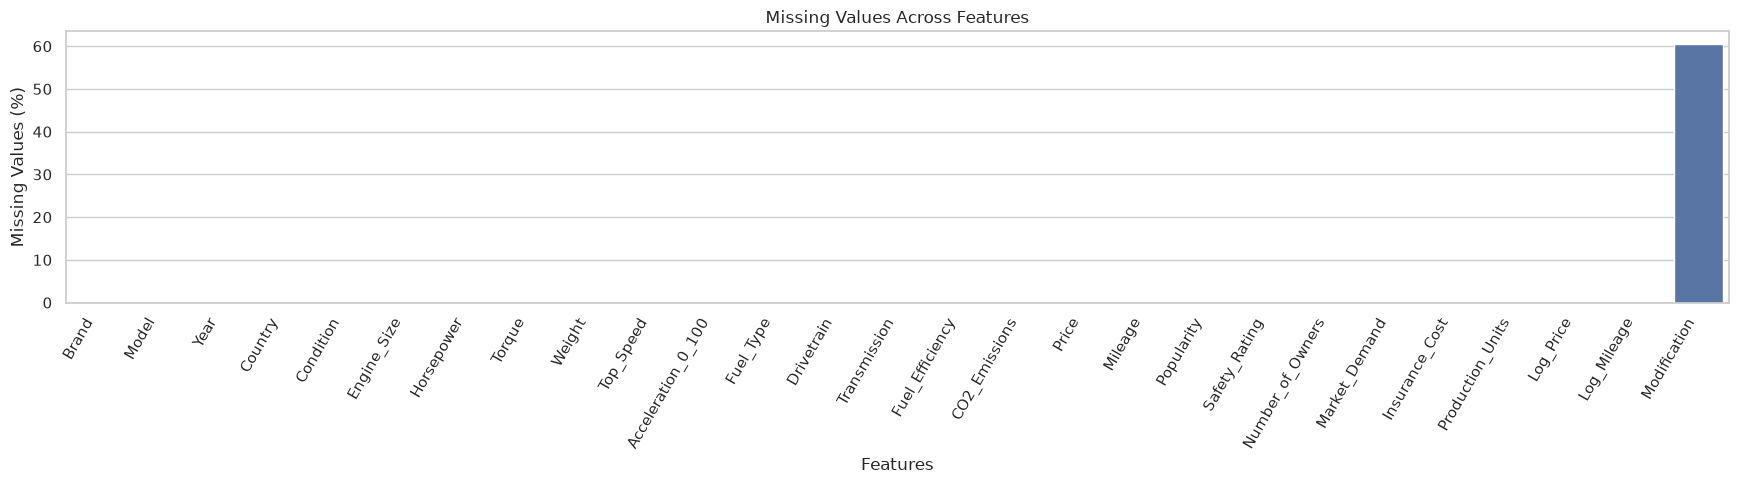

In [257]:
missing_summary = pd.DataFrame({

    "Feature": feature_columns,

    "Type": [
        "Categorical" if col in categorical_features
        else "Numerical" if col in numeric_features
        else "Datetime"
        for col in feature_columns
    ],

    "Valid N": [
        df[col].notna().sum()
        for col in feature_columns
    ],

    "Missing N": [
        df[col].isna().sum()
        for col in feature_columns
    ],

    "Missing %": [
        df[col].isna().mean() * 100
        for col in feature_columns
    ]
})

display(
    missing_summary.sort_values(
        "Missing %",
        ascending=False
    )
)


# Missingness visualisation
plt.figure(figsize=(max(8, len(feature_columns) * 0.65), 5))

sns.barplot(
    data=missing_summary,
    x="Feature",
    y="Missing %"
)

plt.title("Missing Values Across Features")
plt.ylabel("Missing Values (%)")
plt.xlabel("Features")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()


Categorical feature: Brand


,Category,Count,Percentage
0,Ferrari,533,10.66
1,Chevrolet,516,10.32
2,Porsche,513,10.26
3,Aston Martin,513,10.26
4,Bugatti,507,10.14
5,BMW,496,9.92
6,McLaren,486,9.72
7,Ford,486,9.72
8,Nissan,480,9.60
9,Lamborghini,470,9.40


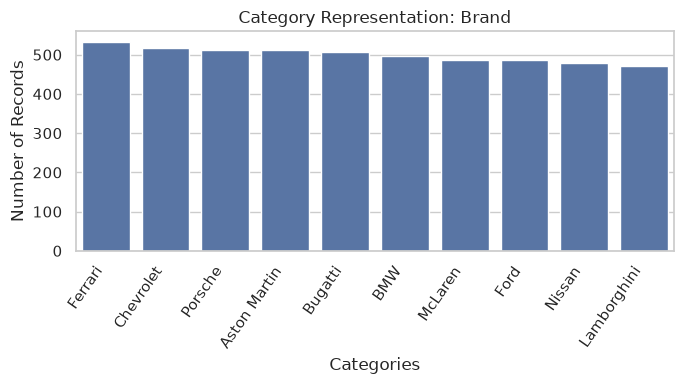


Categorical feature: Model


,Category,Count,Percentage
0,M4 Competition,538,10.76
1,GT-R,537,10.74
2,488 GTB,520,10.40
3,Huracan,515,10.30
4,Mustang GT,508,10.16
5,DBS,508,10.16
6,720S,485,9.70
7,911 Turbo S,483,9.66
8,Chiron,455,9.10
9,Corvette Z06,451,9.02


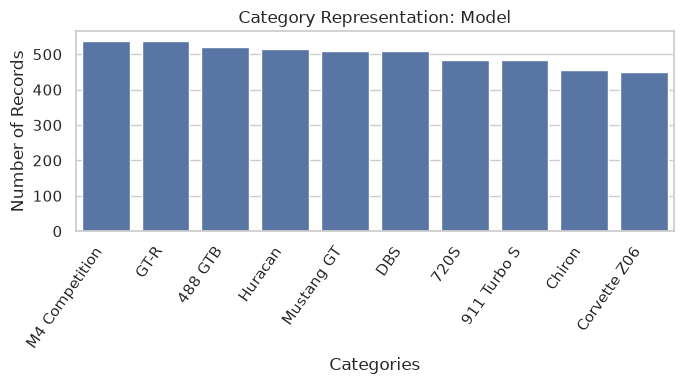


Categorical feature: Country


,Category,Count,Percentage
0,Asia,1677,33.54
1,Europe,1676,33.52
2,USA,1647,32.94


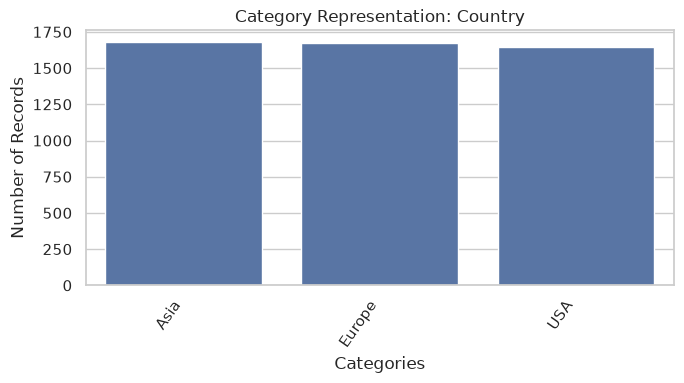


Categorical feature: Condition


,Category,Count,Percentage
0,new,2559,51.18
1,used,1824,36.48
2,salvage,495,9.90
3,restored,122,2.44


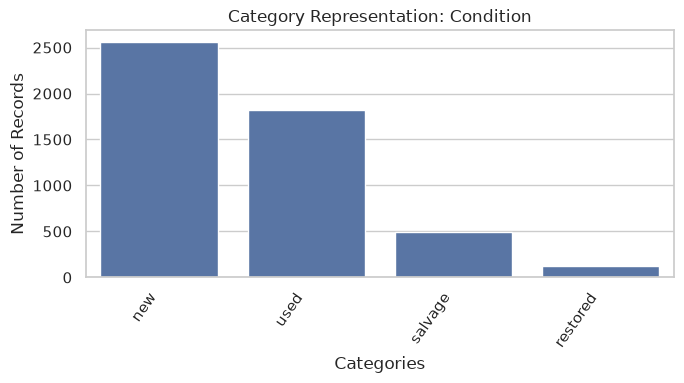


Categorical feature: Fuel_Type


,Category,Count,Percentage
0,Petrol,1688,33.76
1,Diesel,1684,33.68
2,Electric,1628,32.56


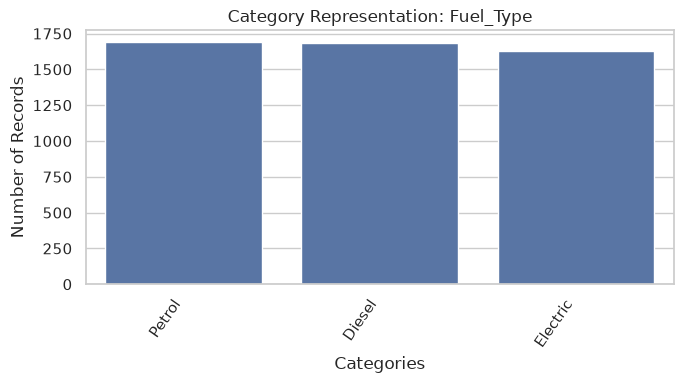


Categorical feature: Drivetrain


,Category,Count,Percentage
0,RWD,1681,33.62
1,AWD,1677,33.54
2,FWD,1642,32.84


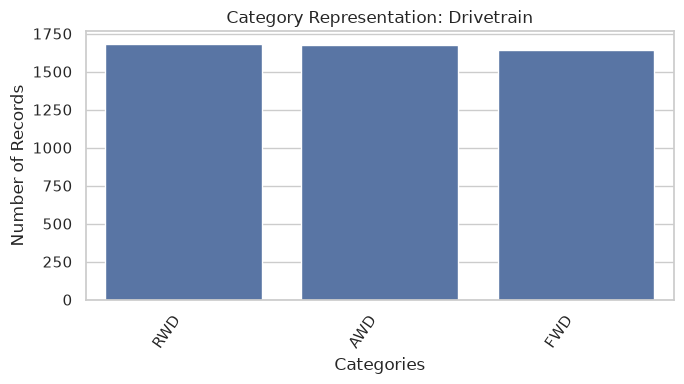


Categorical feature: Transmission


,Category,Count,Percentage
0,CVT,1267,25.34
1,Automatic,1265,25.30
2,DCT,1237,24.74
3,Manual,1231,24.62


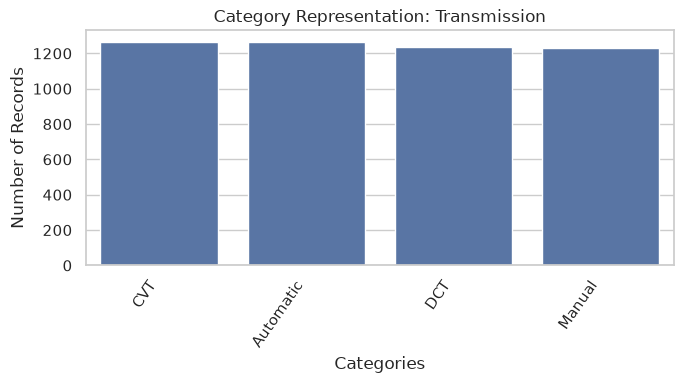


Categorical feature: Popularity


,Category,Count,Percentage
0,Low,2001,40.02
1,High,1985,39.70
2,Medium,1014,20.28


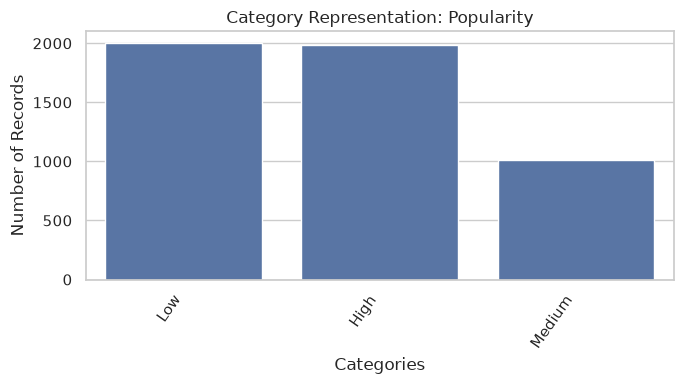


Categorical feature: Market_Demand


,Category,Count,Percentage
0,Low,1704,34.08
1,Medium,1678,33.56
2,High,1618,32.36


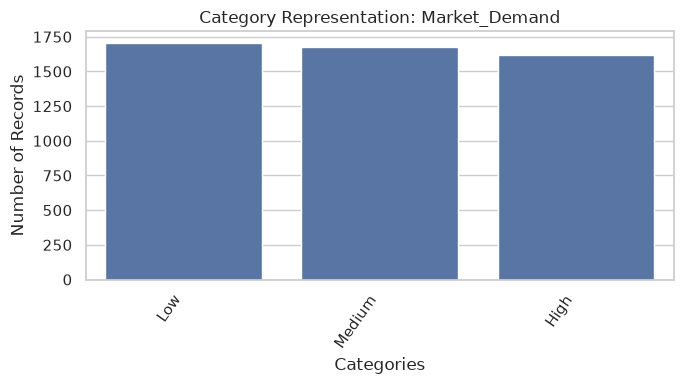


Categorical feature: Modification


,Category,Count,Percentage
0,RS,270,13.657056
1,Nismo,260,13.151239
2,Turbo,250,12.645422
3,Supercharged,249,12.594841
4,Track Edition,242,12.240769
5,V-Spec,239,12.089024
6,Sport,238,12.038442
7,GT,229,11.583207


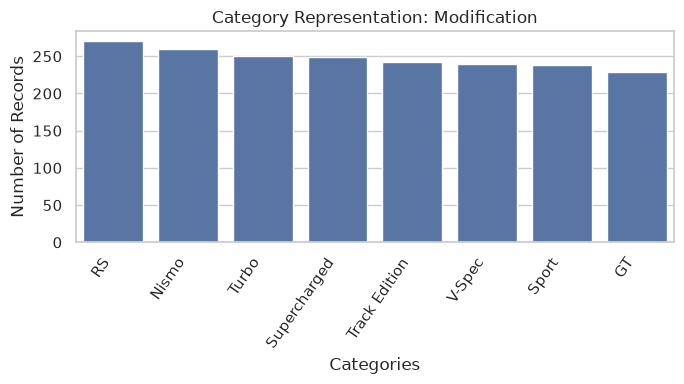

In [258]:
categorical_frequencies = {}

for col in categorical_features:

    freq = (
        df[col]
        .value_counts(dropna=True)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    freq["Percentage"] = (
        freq["Count"] / max(freq["Count"].sum(), 1) * 100
    )

    categorical_frequencies[col] = freq

    print(f"\nCategorical feature: {col}")

    display(freq)

    if not freq.empty:

        plt.figure(
            figsize=(max(7, min(14, len(freq) * 0.6)), 4)
        )

        sns.barplot(
            data=freq,
            x="Category",
            y="Count"
        )

        plt.title(f"Category Representation: {col}")
        plt.xlabel("Categories")
        plt.ylabel("Number of Records")

        plt.xticks(rotation=55, ha="right")
        plt.tight_layout()
        plt.show()


Numerical feature: Year


,Fixed-width bin,Count,Percentage
0,"(1979.999, 1984.4]",528,10.56
1,"(1984.4, 1988.8]",447,8.94
2,"(1988.8, 1993.2]",564,11.28
3,"(1993.2, 1997.6]",488,9.76
4,"(1997.6, 2002.0]",589,11.78
5,"(2002.0, 2006.4]",442,8.84
6,"(2006.4, 2010.8]",436,8.72
7,"(2010.8, 2015.2]",513,10.26
8,"(2015.2, 2019.6]",441,8.82
9,"(2019.6, 2024.0]",552,11.04


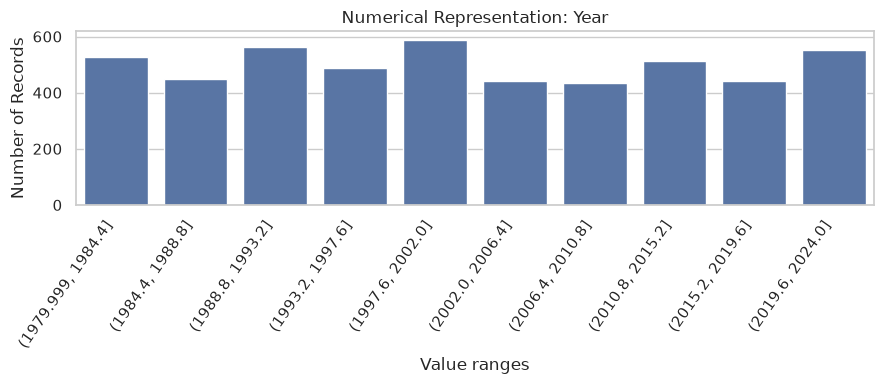


Numerical feature: Engine_Size


,Fixed-width bin,Count,Percentage
0,"(1.5990000000000002, 2.24]",479,9.58
1,"(2.24, 2.88]",480,9.60
2,"(2.88, 3.52]",565,11.30
3,"(3.52, 4.16]",472,9.44
4,"(4.16, 4.8]",529,10.58
5,"(4.8, 5.44]",453,9.06
6,"(5.44, 6.08]",439,8.78
7,"(6.08, 6.72]",572,11.44
8,"(6.72, 7.36]",470,9.40
9,"(7.36, 8.0]",541,10.82


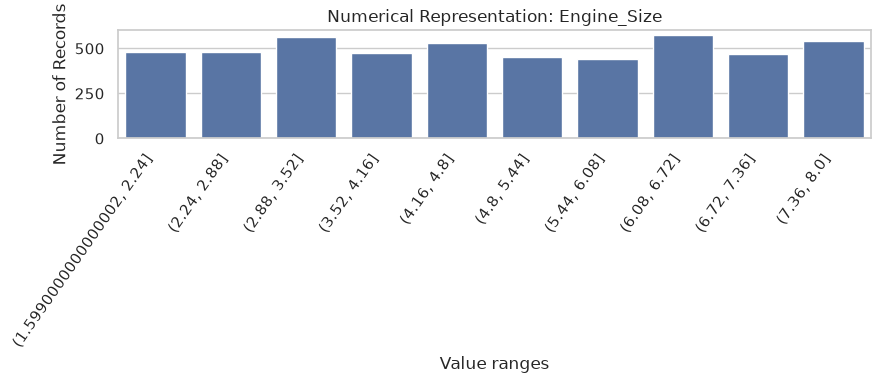


Numerical feature: Horsepower


,Fixed-width bin,Count,Percentage
0,"(129.999, 269.1]",493,9.86
1,"(269.1, 408.2]",506,10.12
2,"(408.2, 547.3]",518,10.36
3,"(547.3, 686.4]",524,10.48
4,"(686.4, 825.5]",480,9.60
5,"(825.5, 964.6]",467,9.34
6,"(964.6, 1103.7]",509,10.18
7,"(1103.7, 1242.8]",517,10.34
8,"(1242.8, 1381.9]",498,9.96
9,"(1381.9, 1521.0]",488,9.76


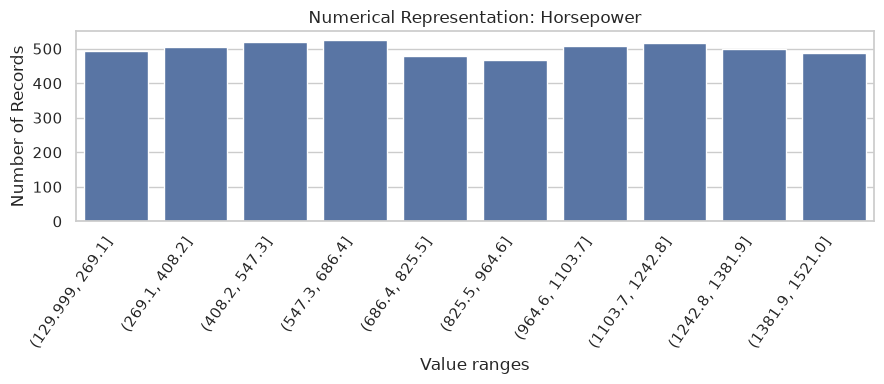


Numerical feature: Torque


,Fixed-width bin,Count,Percentage
0,"(119.999, 283.8]",498,9.96
1,"(283.8, 447.6]",517,10.34
2,"(447.6, 611.4]",494,9.88
3,"(611.4, 775.2]",483,9.66
4,"(775.2, 939.0]",476,9.52
5,"(939.0, 1102.8]",516,10.32
6,"(1102.8, 1266.6]",521,10.42
7,"(1266.6, 1430.4]",508,10.16
8,"(1430.4, 1594.2]",504,10.08
9,"(1594.2, 1758.0]",483,9.66


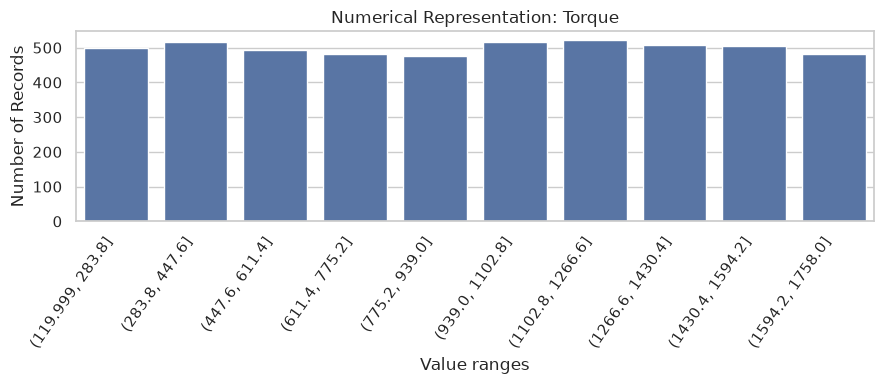


Numerical feature: Weight


,Fixed-width bin,Count,Percentage
0,"(899.999, 1059.9]",553,11.06
1,"(1059.9, 1219.8]",513,10.26
2,"(1219.8, 1379.7]",456,9.12
3,"(1379.7, 1539.6]",534,10.68
4,"(1539.6, 1699.5]",483,9.66
5,"(1699.5, 1859.4]",509,10.18
6,"(1859.4, 2019.3]",467,9.34
7,"(2019.3, 2179.2]",488,9.76
8,"(2179.2, 2339.1]",498,9.96
9,"(2339.1, 2499.0]",499,9.98


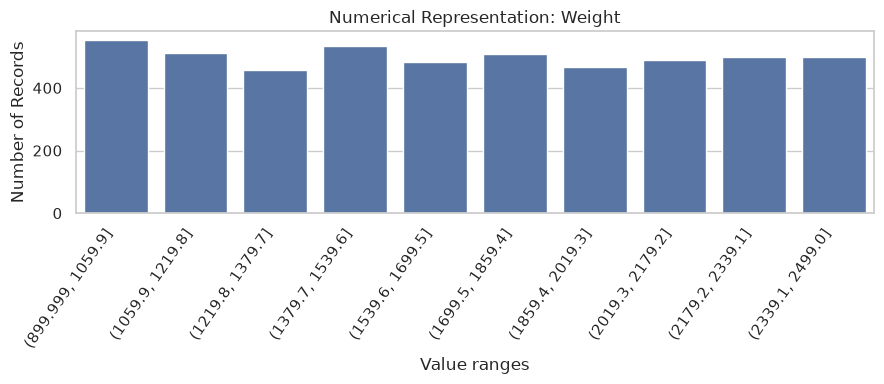


Numerical feature: Top_Speed


,Fixed-width bin,Count,Percentage
0,"(149.999, 174.9]",497,9.94
1,"(174.9, 199.8]",486,9.72
2,"(199.8, 224.7]",477,9.54
3,"(224.7, 249.6]",523,10.46
4,"(249.6, 274.5]",516,10.32
5,"(274.5, 299.4]",508,10.16
6,"(299.4, 324.3]",465,9.30
7,"(324.3, 349.2]",530,10.60
8,"(349.2, 374.1]",481,9.62
9,"(374.1, 399.0]",517,10.34


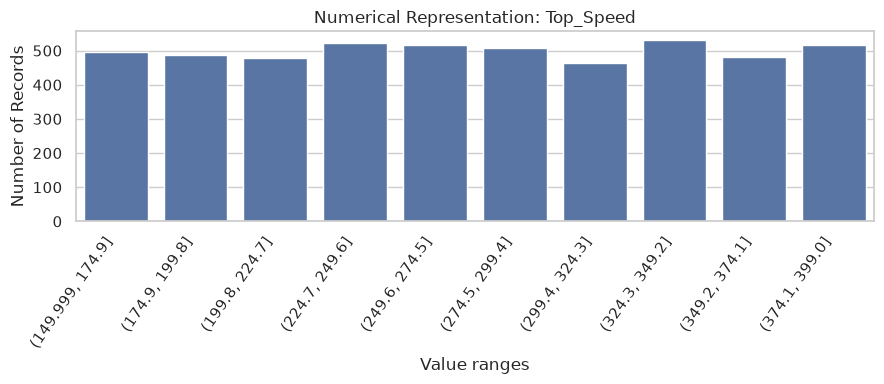


Numerical feature: Acceleration_0_100


,Fixed-width bin,Count,Percentage
0,"(1.999, 2.5]",546,10.92
1,"(2.5, 3.0]",474,9.48
2,"(3.0, 3.5]",518,10.36
3,"(3.5, 4.0]",500,10.00
4,"(4.0, 4.5]",522,10.44
5,"(4.5, 5.0]",487,9.74
6,"(5.0, 5.5]",494,9.88
7,"(5.5, 6.0]",489,9.78
8,"(6.0, 6.5]",461,9.22
9,"(6.5, 7.0]",509,10.18


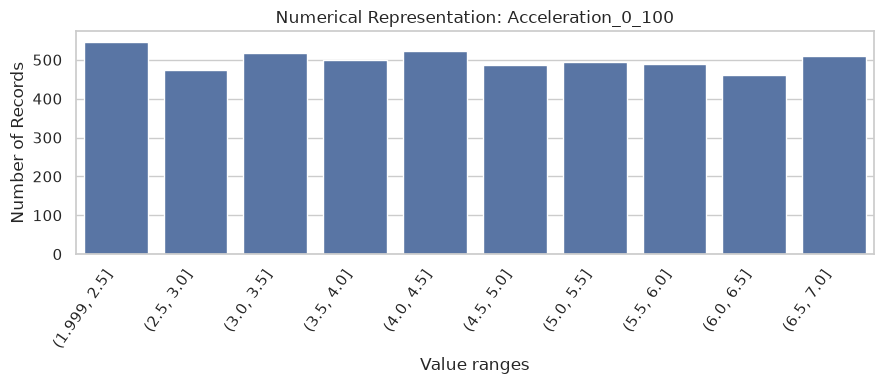


Numerical feature: Fuel_Efficiency


,Fixed-width bin,Count,Percentage
0,"(4.999, 6.0]",509,10.18
1,"(6.0, 7.0]",493,9.86
2,"(7.0, 8.0]",467,9.34
3,"(8.0, 9.0]",496,9.92
4,"(9.0, 10.0]",543,10.86
5,"(10.0, 11.0]",509,10.18
6,"(11.0, 12.0]",469,9.38
7,"(12.0, 13.0]",508,10.16
8,"(13.0, 14.0]",540,10.80
9,"(14.0, 15.0]",466,9.32


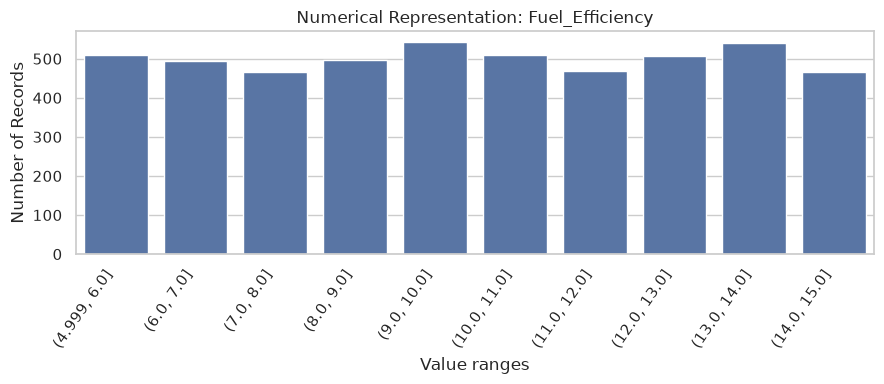


Numerical feature: CO2_Emissions


,Fixed-width bin,Count,Percentage
0,"(99.999, 134.9]",497,9.94
1,"(134.9, 169.8]",503,10.06
2,"(169.8, 204.7]",536,10.72
3,"(204.7, 239.6]",473,9.46
4,"(239.6, 274.5]",507,10.14
5,"(274.5, 309.4]",535,10.70
6,"(309.4, 344.3]",519,10.38
7,"(344.3, 379.2]",485,9.70
8,"(379.2, 414.1]",454,9.08
9,"(414.1, 449.0]",491,9.82


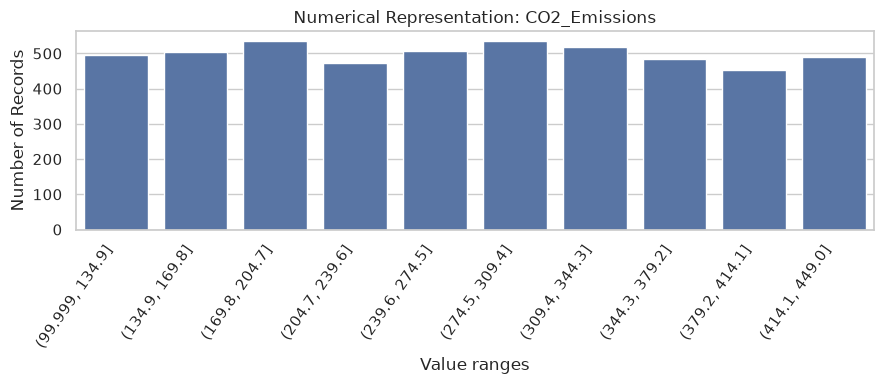


Numerical feature: Price


,Fixed-width bin,Count,Percentage
0,"(20013.999, 68011.7]",501,10.02
1,"(68011.7, 116009.4]",473,9.46
2,"(116009.4, 164007.1]",482,9.64
3,"(164007.1, 212004.8]",501,10.02
4,"(212004.8, 260002.5]",486,9.72
5,"(260002.5, 308000.2]",503,10.06
6,"(308000.2, 355997.9]",545,10.90
7,"(355997.9, 403995.6]",522,10.44
8,"(403995.6, 451993.3]",513,10.26
9,"(451993.3, 499991.0]",474,9.48


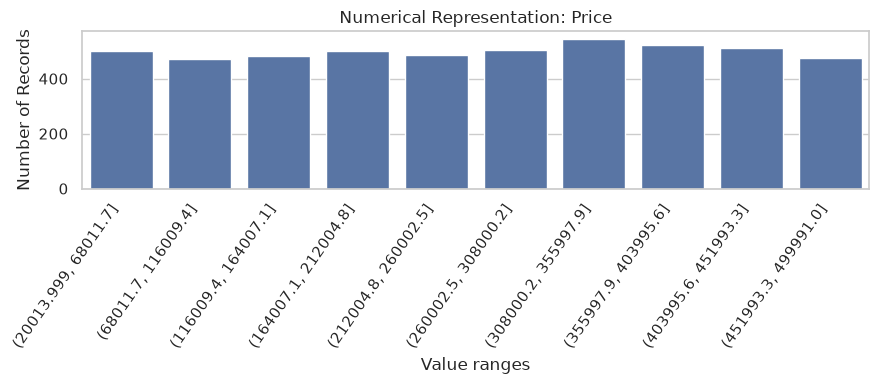


Numerical feature: Mileage


,Fixed-width bin,Count,Percentage
0,"(46.999, 25037.9]",494,9.88
1,"(25037.9, 50028.8]",499,9.98
2,"(50028.8, 75019.7]",518,10.36
3,"(75019.7, 100010.6]",499,9.98
4,"(100010.6, 125001.5]",451,9.02
5,"(125001.5, 149992.4]",473,9.46
6,"(149992.4, 174983.3]",492,9.84
7,"(174983.3, 199974.2]",549,10.98
8,"(199974.2, 224965.1]",484,9.68
9,"(224965.1, 249956.0]",541,10.82


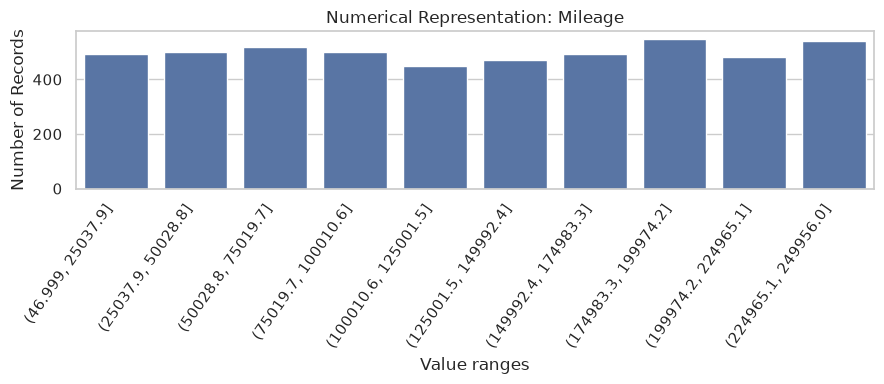


Numerical feature: Safety_Rating


,Fixed-width bin,Count,Percentage
0,"(0.999, 1.3]",1257,25.14
1,"(1.9, 2.2]",1223,24.46
2,"(2.8, 3.1]",1272,25.44
3,"(3.7, 4.0]",1248,24.96


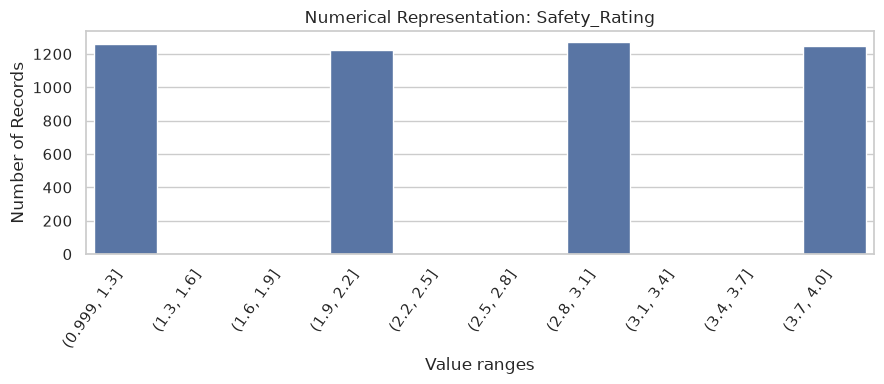


Numerical feature: Number_of_Owners


,Fixed-width bin,Count,Percentage
0,"(0.999, 1.3]",1274,25.48
1,"(1.9, 2.2]",1262,25.24
2,"(2.8, 3.1]",1258,25.16
3,"(3.7, 4.0]",1206,24.12


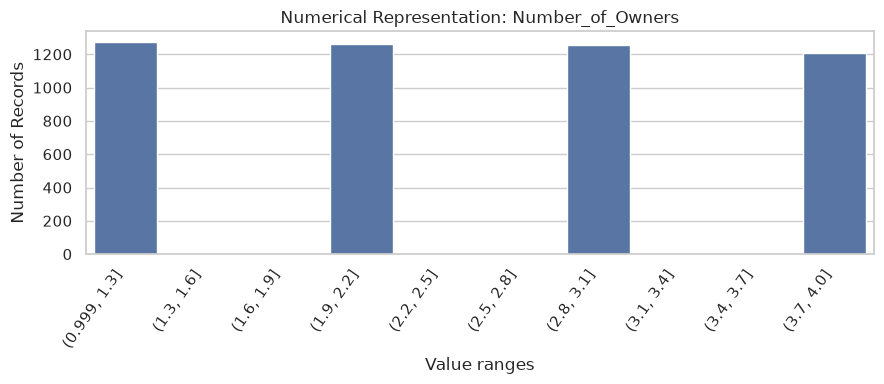


Numerical feature: Insurance_Cost


,Fixed-width bin,Count,Percentage
0,"(500.999, 1950.7]",481,9.62
1,"(1950.7, 3400.4]",509,10.18
2,"(3400.4, 4850.1]",513,10.26
3,"(4850.1, 6299.8]",511,10.22
4,"(6299.8, 7749.5]",507,10.14
5,"(7749.5, 9199.2]",484,9.68
6,"(9199.2, 10648.9]",502,10.04
7,"(10648.9, 12098.6]",482,9.64
8,"(12098.6, 13548.3]",518,10.36
9,"(13548.3, 14998.0]",493,9.86


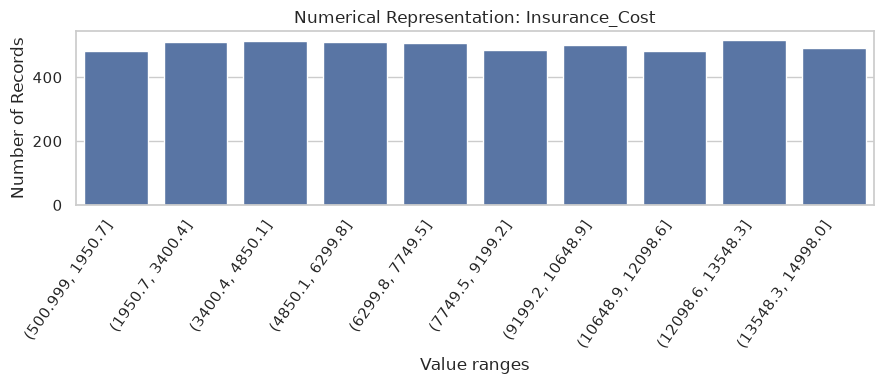


Numerical feature: Production_Units


,Fixed-width bin,Count,Percentage
0,"(49.999, 10045.0]",2532,50.64
1,"(10045.0, 20040.0]",1504,30.08
2,"(90005.0, 100000.0]",964,19.28


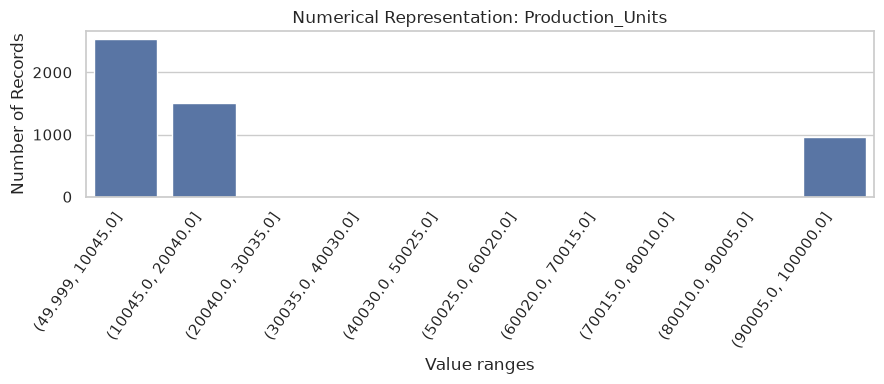


Numerical feature: Log_Price


,Fixed-width bin,Count,Percentage
0,"(9.903, 10.226]",86,1.72
1,"(10.226, 10.548]",110,2.20
2,"(10.548, 10.87]",136,2.72
3,"(10.87, 11.191]",209,4.18
4,"(11.191, 11.513]",269,5.38
5,"(11.513, 11.835]",385,7.70
6,"(11.835, 12.157]",520,10.40
7,"(12.157, 12.479]",765,15.30
8,"(12.479, 12.801]",1071,21.42
9,"(12.801, 13.122]",1449,28.98


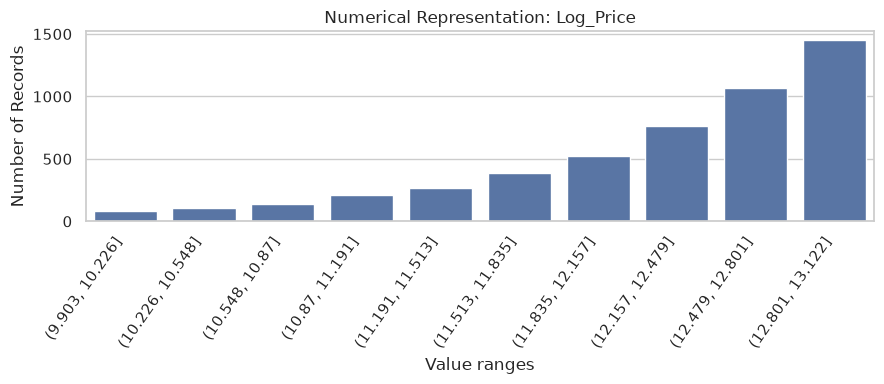


Numerical feature: Log_Mileage


,Fixed-width bin,Count,Percentage
0,"(3.87, 4.727]",1,0.02
1,"(4.727, 5.583]",1,0.02
2,"(5.583, 6.439]",9,0.18
3,"(6.439, 7.294]",16,0.32
4,"(7.294, 8.15]",32,0.64
5,"(8.15, 9.006]",87,1.74
6,"(9.006, 9.862]",217,4.34
7,"(9.862, 10.717]",526,10.52
8,"(10.717, 11.573]",1238,24.76
9,"(11.573, 12.429]",2873,57.46


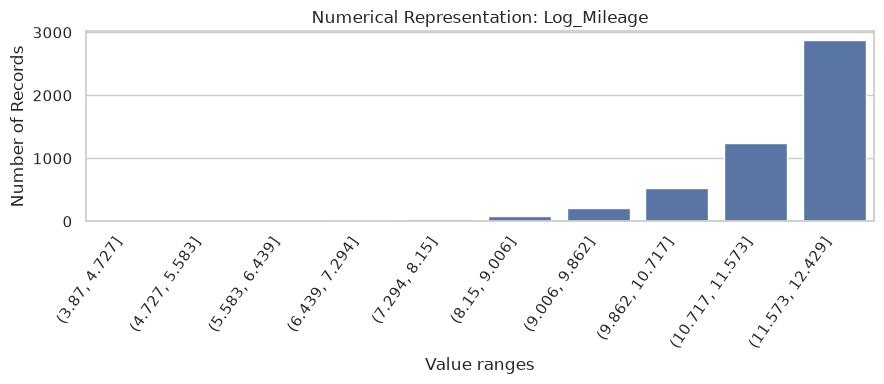

In [259]:
numeric_binnings = {}

for col in numeric_features:

    values = df[col].dropna()

    if values.empty:
        continue

    if values.nunique() <= 1:

        counts = values.value_counts().sort_index()

    else:

        bin_edges = np.linspace(
            values.min(),
            values.max(),
            NUMERIC_BINS + 1
        )

        binned = pd.cut(
            values,
            bins=np.unique(bin_edges),
            include_lowest=True,
            duplicates="drop"
        )

        counts = binned.value_counts(sort=False)

    numeric_binnings[col] = counts

    freq = (
        counts[counts > 0]
        .rename_axis("Fixed-width bin")
        .reset_index(name="Count")
    )

    freq["Percentage"] = (
        freq["Count"] / max(freq["Count"].sum(), 1) * 100
    )

    print(f"\nNumerical feature: {col}")

    display(freq)

    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=freq,
        x="Fixed-width bin",
        y="Count"
    )

    plt.title(f"Numerical Representation: {col}")
    plt.xlabel("Value ranges")
    plt.ylabel("Number of Records")

    plt.xticks(rotation=55, ha="right")
    plt.tight_layout()
    plt.show()

In [260]:
datetime_profiles = {}

for col in datetime_features:

    dates = df[col].dropna()

    if dates.empty:
        continue

    monthly_counts = (
        dates.dt.to_period("M")
        .value_counts()
        .sort_index()
    )

    profile = (
        monthly_counts
        .rename_axis("Month")
        .reset_index(name="Count")
    )

    datetime_profiles[col] = profile

    print(f"\nDatetime feature: {col}")

    display(profile)

    plt.figure(figsize=(10, 4))

    sns.lineplot(
        data=profile,
        x="Month",
        y="Count",
        marker="o"
    )

    plt.title(f"Temporal Representation: {col}")
    plt.xlabel("Month")
    plt.ylabel("Number of Records")

    plt.xticks(rotation=55, ha="right")
    plt.tight_layout()
    plt.show()

In [261]:
def calculate_ir_nis(counts):

    counts = np.asarray(counts, dtype=float)

    counts = counts[
        np.isfinite(counts) & (counts > 0)
    ]

    if len(counts) <= 1:
        return np.nan, np.nan

    ir = counts.max() / counts.min()

    nis = 1 - (1 / ir)

    return float(ir), float(nis)


def calculate_jsd_uniform(counts):

    counts = np.asarray(counts, dtype=float)

    counts = counts[
        np.isfinite(counts) & (counts > 0)
    ]

    if len(counts) <= 1:
        return np.nan

    observed = counts / counts.sum()

    uniform = np.full(
        len(observed),
        1 / len(observed)
    )

    # scipy returns the square root of JSD divergence
    jsd = jensenshannon(
        observed,
        uniform,
        base=2
    ) ** 2

    return float(jsd)


def calculate_metrics(counts):

    ir, nis = calculate_ir_nis(counts)

    jsd = calculate_jsd_uniform(counts)

    return ir, nis, jsd


# Formula validation
print("Balanced 50:50:", calculate_metrics([50, 50]))
print("Imbalanced 80:20:", calculate_metrics([80, 20]))
print("Imbalanced 90:10:", calculate_metrics([90, 10]))

Balanced 50:50: (1.0, 0.0, 0.0)
Imbalanced 80:20: (4.0, 0.75, 0.0731040079318099)
Imbalanced 90:10: (9.0, 0.8888888888888888, 0.14679310243605215)


In [262]:

# ============================================================
# CATEGORY RARITY ANALYSIS for extereme cases
# ============================================================

VERY_RARE_MAX_COUNT = 5
VERY_RARE_MAX_PERCENT = 0.1

RARE_MAX_COUNT = 20
RARE_MAX_PERCENT = 1.0

LOW_REPRESENTATION_PERCENT = 5.0


def classify_category(count, percentage):

    if (count <= VERY_RARE_MAX_COUNT or
            percentage < VERY_RARE_MAX_PERCENT):
        return "Very rare"

    elif (count <= RARE_MAX_COUNT or
            percentage < RARE_MAX_PERCENT):
        return "Rare"

    elif percentage < LOW_REPRESENTATION_PERCENT:
        return "Low representation"

    return "No rarity flag"


rare_category_rows = []

for col in categorical_features:

    valid_values = df[col].dropna()
    total_valid = len(valid_values)

    if total_valid == 0:
        continue

    counts = valid_values.value_counts()

    for category, count in counts.items():

        percentage = count / total_valid * 100

        rare_category_rows.append({
            "Feature": col,
            "Category": str(category),
            "Count": int(count),
            "Percentage": percentage,
            "Rarity Flag": classify_category(
                int(count), percentage
            )
        })


rare_category_df = pd.DataFrame(rare_category_rows)

print("CATEGORY RARITY ANALYSIS")
display(rare_category_df.round(4))


CATEGORY RARITY ANALYSIS


,Feature,Category,Count,Percentage,Rarity Flag
0,Brand,Ferrari,533,10.6600,No rarity flag
1,Brand,Chevrolet,516,10.3200,No rarity flag
2,Brand,Porsche,513,10.2600,No rarity flag
3,Brand,Aston Martin,513,10.2600,No rarity flag
4,Brand,Bugatti,507,10.1400,No rarity flag
5,Brand,BMW,496,9.9200,No rarity flag
6,Brand,McLaren,486,9.7200,No rarity flag
7,Brand,Ford,486,9.7200,No rarity flag
8,Brand,Nissan,480,9.6000,No rarity flag
9,Brand,Lamborghini,470,9.4000,No rarity flag


In [263]:
metric_rows = []

# Categorical features
#for col in categorical_features:

   # counts = df[col].value_counts(dropna=True).values

    #ir, nis, jsd = calculate_metrics(counts)

    #metric_rows.append({
       # "Feature": col,
        #"Type": "Categorical",
        #"Valid N": int(df[col].notna().sum()),
        #"Missing %": df[col].isna().mean() * 100,
        #"IR": ir,
        #"NIS": nis,
        #"JSD": jsd
    #})


# Categorical features
for col in categorical_features:

    valid_values = df[col].dropna()
    counts_series = valid_values.value_counts()

    counts = counts_series.values

    ir, nis, jsd = calculate_metrics(counts)

    # Supplementary top-two comparison
    if len(counts) >= 2:
        nis_top2 = 1 - (
            counts_series.iloc[1] /
            counts_series.iloc[0]
        )
    else:
        nis_top2 = np.nan

    # Count very rare and rare categories
    feature_rarity = rare_category_df[
        (rare_category_df["Feature"] == col) &
        (rare_category_df["Rarity Flag"].isin(
            ["Very rare", "Rare"]
        ))
    ]

    metric_rows.append({
        "Feature": col,
        "Type": "Categorical",
        "Valid N": int(valid_values.shape[0]),
        "Missing %": df[col].isna().mean() * 100,
        "IR": ir,
        "NIS": nis,
        "NIS Top-2": nis_top2,
        "Rare Categories": len(feature_rarity),
        "JSD": jsd
    })

# Numerical features
for col in numeric_features:

    counts = (
        numeric_binnings[col].values
        if col in numeric_binnings
        else []
    )

    ir, nis, jsd = calculate_metrics(counts)

    metric_rows.append({
        "Feature": col,
        "Type": "Numerical",
        "Valid N": int(df[col].notna().sum()),
        "Missing %": df[col].isna().mean() * 100,
        "IR": ir,
        "NIS": nis,
        "JSD": jsd,
        "NIS Top-2": np.nan,
"Rare Categories": np.nan,
    })


# Create feature-level table
feature_results = pd.DataFrame(metric_rows)


if not feature_results.empty:

    # Mean of applicable indicators
    feature_results["Feature Bias Score"] = (
        feature_results[["NIS", "JSD"]]
        .mean(axis=1, skipna=True)
    )

    # Number of applicable indicators
    feature_results["Applicable Indicators"] = (
        feature_results[["NIS", "JSD"]]
        .notna()
        .sum(axis=1)
    )

    eligible = feature_results[
        "Feature Bias Score"
    ].notna()

    dataset_bias = (
        feature_results.loc[
            eligible,
            "Feature Bias Score"
        ].mean()
        if eligible.any()
        else np.nan
    )

else:

    feature_results = pd.DataFrame(
        columns=[
            "Feature",
            "Type",
            "Valid N",
            "Missing %",
            "IR",
            "NIS",
            "JSD",
            "Feature Bias Score",
            "Applicable Indicators"
        ]
    )

    dataset_bias = np.nan


# Proposed objectivity score
dataset_objectivity = (
    1 - dataset_bias
    if pd.notna(dataset_bias)
    else np.nan
)


# Final feature-level table
final_feature_table = feature_results[
    [
        "Feature",
        "Type",
        "Valid N",
        "Missing %",
        "IR",
        "NIS",
        "JSD",
        "Feature Bias Score",
        "Applicable Indicators",
           "NIS Top-2",
        "Rare Categories",
    ]
].copy()


print("FINAL FEATURE-LEVEL RESULTS")

display(
    final_feature_table.round(4)
)


# Dataset-level result
dataset_summary = pd.DataFrame([{
    "Dataset": Path(CSV_PATH).stem,
    "Total Records": len(df),
    "Total Features Analysed": len(feature_results),
    "Eligible Features": int(
        feature_results["Feature Bias Score"].notna().sum()
    ),
    "Aggregate Bias Score": dataset_bias,
    "Proposed Objectivity Score": dataset_objectivity
}])


print("FINAL DATASET-LEVEL RESULTS")

display(dataset_summary.round(4))

FINAL FEATURE-LEVEL RESULTS


,Feature,Type,Valid N,Missing %,IR,NIS,JSD,Feature Bias Score,Applicable Indicators,NIS Top-2,Rare Categories
0,Brand,Categorical,5000,0.00,1.1340,0.1182,0.0002,0.0592,2,0.0319,0.0
1,Model,Categorical,5000,0.00,1.1929,0.1617,0.0006,0.0812,2,0.0019,0.0
2,Country,Categorical,5000,0.00,1.0182,0.0179,0.0000,0.0090,2,0.0006,0.0
3,Condition,Categorical,5000,0.00,20.9754,0.9523,0.1431,0.5477,2,0.2872,0.0
4,Fuel_Type,Categorical,5000,0.00,1.0369,0.0355,0.0000,0.0178,2,0.0024,0.0
5,Drivetrain,Categorical,5000,0.00,1.0238,0.0232,0.0000,0.0116,2,0.0024,0.0
6,Transmission,Categorical,5000,0.00,1.0292,0.0284,0.0000,0.0142,2,0.0016,0.0
7,Popularity,Categorical,5000,0.00,1.9734,0.4933,0.0158,0.2545,2,0.0080,0.0
8,Market_Demand,Categorical,5000,0.00,1.0532,0.0505,0.0001,0.0253,2,0.0153,0.0
9,Modification,Categorical,1977,60.46,1.1790,0.1519,0.0004,0.0761,2,0.0370,0.0


FINAL DATASET-LEVEL RESULTS


,Dataset,Total Records,Total Features Analysed,Eligible Features,Aggregate Bias Score,Proposed Objectivity Score
0,EliteSportsCars_Data,5000,27,27,0.1339,0.8661


Features included in NMI:
['Brand', 'Model', 'Year', 'Country', 'Condition', 'Engine_Size', 'Horsepower', 'Torque', 'Weight', 'Top_Speed', 'Acceleration_0_100', 'Fuel_Type', 'Drivetrain', 'Transmission', 'Fuel_Efficiency', 'CO2_Emissions', 'Price', 'Mileage', 'Popularity', 'Safety_Rating', 'Number_of_Owners', 'Market_Demand', 'Insurance_Cost', 'Production_Units', 'Log_Price', 'Log_Mileage', 'Modification']
PAIRWISE NMI RESULTS


,Feature 1,Feature 2,NMI,Pairwise Valid N
0,Brand,Model,0.0029,5000
1,Brand,Year,0.0042,5000
2,Brand,Country,0.0014,5000
3,Brand,Condition,0.0023,5000
4,Brand,Engine_Size,0.0026,5000
...,...,...,...,...
346,Production_Units,Log_Mileage,0.0013,5000
347,Production_Units,Modification,0.0025,1977
348,Log_Price,Log_Mileage,0.0029,5000
349,Log_Price,Modification,0.0063,1977


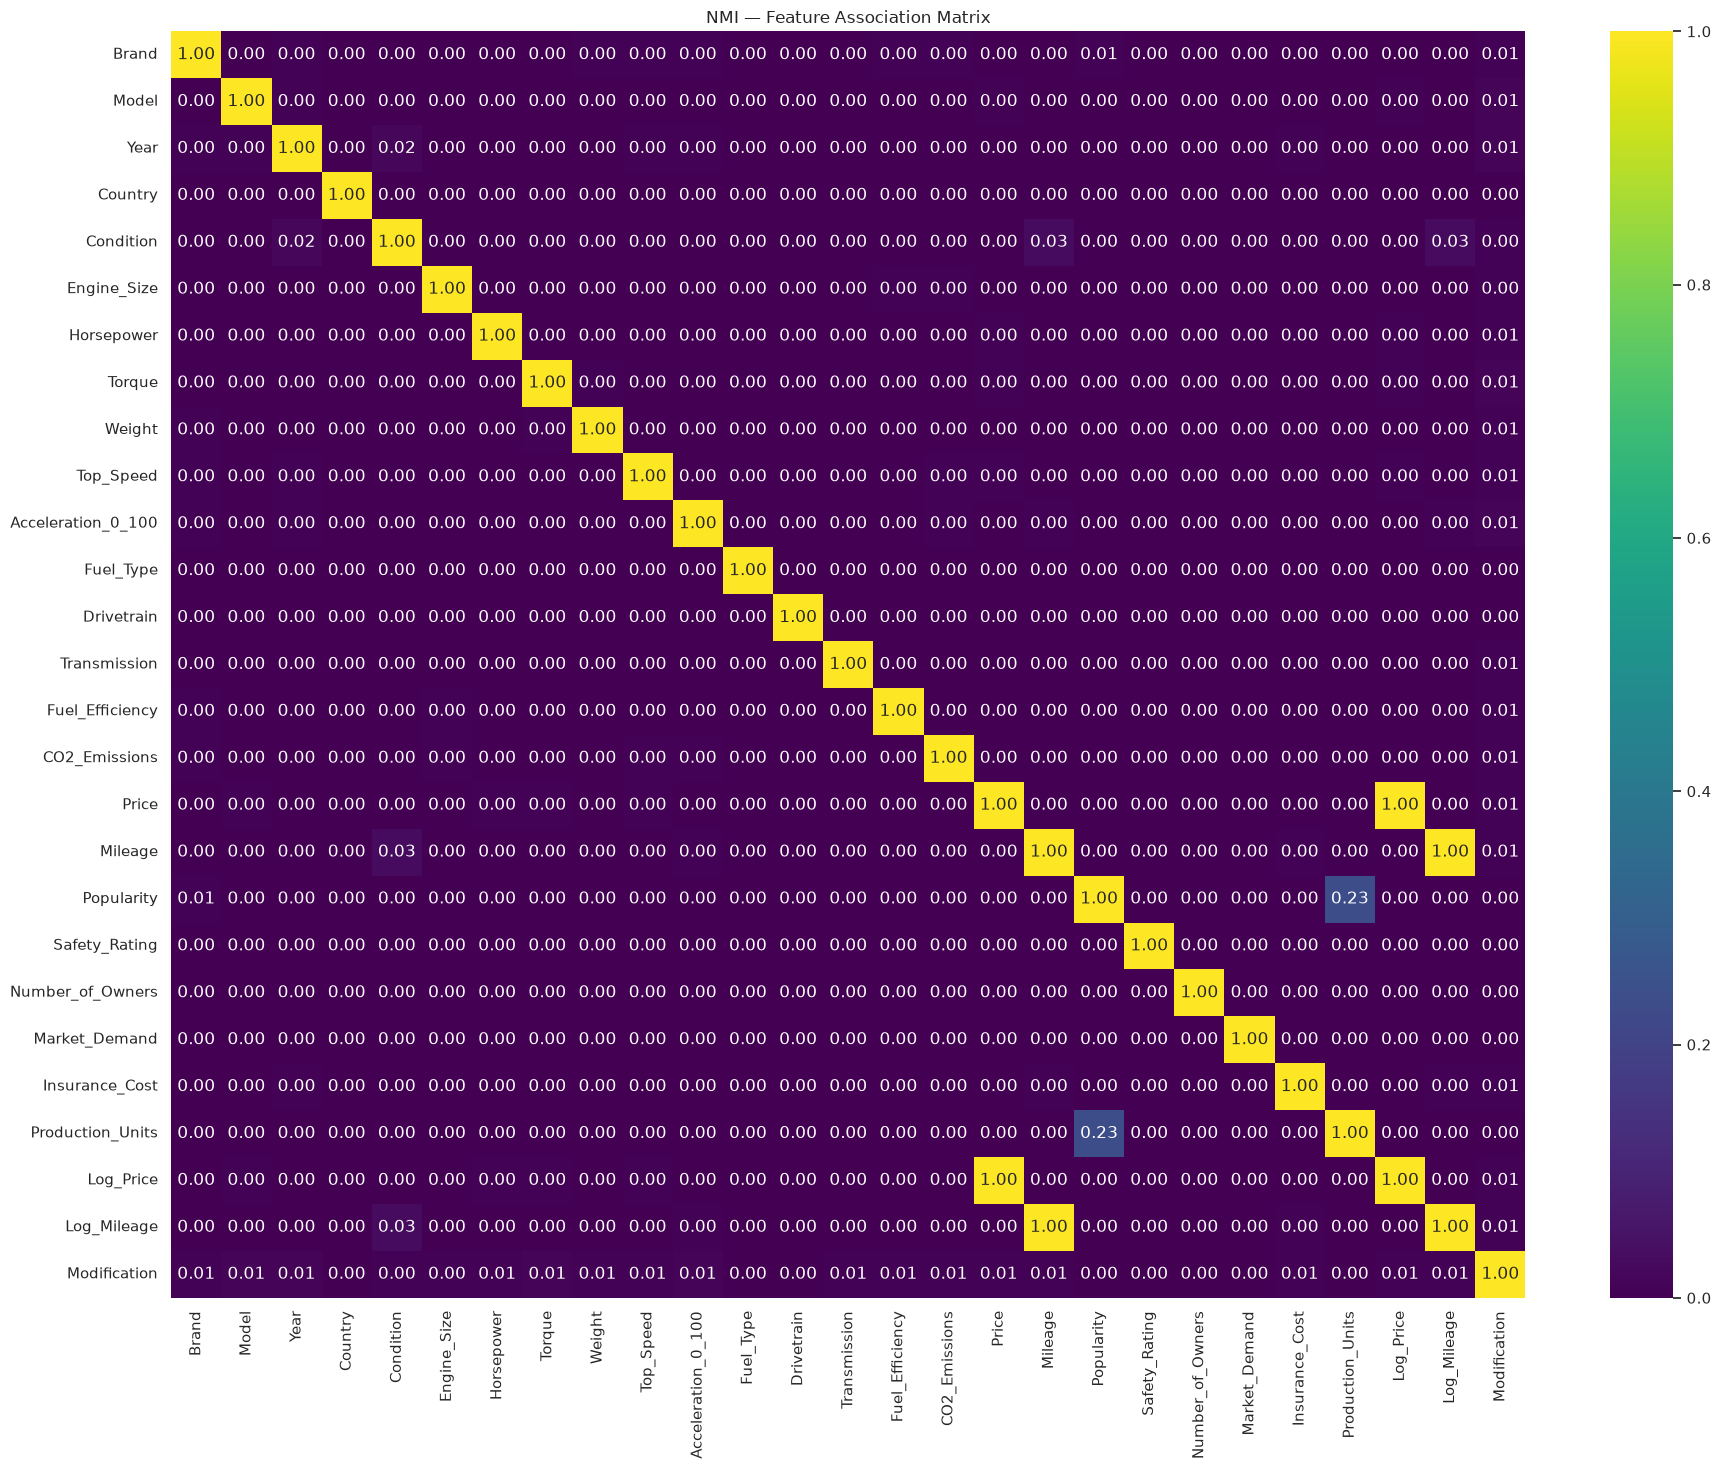

In [264]:
def prepare_for_nmi(series):

    if pd.api.types.is_datetime64_any_dtype(series):

        return series.dt.to_period("M").astype("string")

    if pd.api.types.is_numeric_dtype(series):

        if series.dropna().nunique() <= 1:
            return pd.Series(np.nan, index=series.index)

        bins = min(
            NMI_NUMERIC_BINS,
            series.dropna().nunique()
        )

        return pd.qcut(
            series,
            q=bins,
            duplicates="drop"
        ).astype("string")

    return series.astype("string")


# Only analytical features are considered.
# ID and target are excluded through feature_columns.
nmi_features = [
    col for col in feature_columns
    if col in categorical_features
    or col in numeric_features
    or col in datetime_features
]

print("Features included in NMI:")
print(nmi_features)

nmi_data = {
    col: prepare_for_nmi(df[col])
    for col in nmi_features
}


nmi_rows = []

for col_a, col_b in combinations(nmi_features, 2):

    pair = pd.DataFrame({
        "A": nmi_data[col_a],
        "B": nmi_data[col_b]
    }).dropna()

    if (
        len(pair) < MIN_NMI_VALID_PAIRS
        or pair["A"].nunique() <= 1
        or pair["B"].nunique() <= 1
    ):
        continue

    nmi = normalized_mutual_info_score(
        pair["A"],
        pair["B"],
        average_method="arithmetic"
    )

    nmi_rows.append({
        "Feature 1": col_a,
        "Feature 2": col_b,
        "NMI": nmi,
        "Pairwise Valid N": len(pair)
    })


nmi_results = pd.DataFrame(
    nmi_rows,
    columns=[
        "Feature 1",
        "Feature 2",
        "NMI",
        "Pairwise Valid N"
    ]
)


print("PAIRWISE NMI RESULTS")

display(nmi_results.round(4))


# NMI heatmap
if not nmi_results.empty:

    nmi_matrix = pd.DataFrame(
        np.eye(len(nmi_features)),
        index=nmi_features,
        columns=nmi_features
    )

    for _, row in nmi_results.iterrows():

        a = row["Feature 1"]
        b = row["Feature 2"]

        nmi_matrix.loc[a, b] = row["NMI"]
        nmi_matrix.loc[b, a] = row["NMI"]


    plt.figure(
        figsize=(
            max(7, len(nmi_features) * 0.7),
            max(5, len(nmi_features) * 0.55)
        )
    )

    sns.heatmap(
        nmi_matrix,
        annot=True,
        fmt=".2f",
        cmap="viridis",
        vmin=0,
        vmax=1
    )

    plt.title("NMI — Feature Association Matrix")
    plt.tight_layout()
    plt.show()

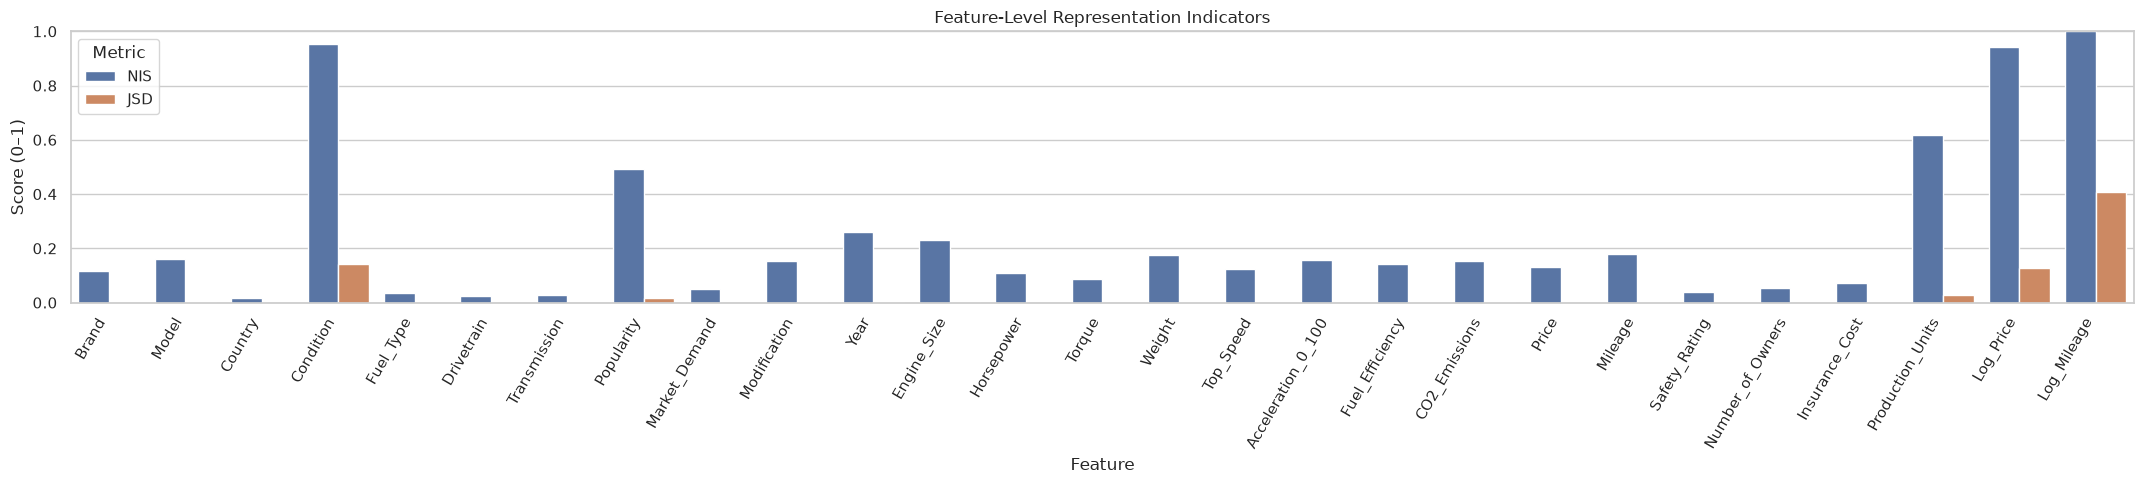

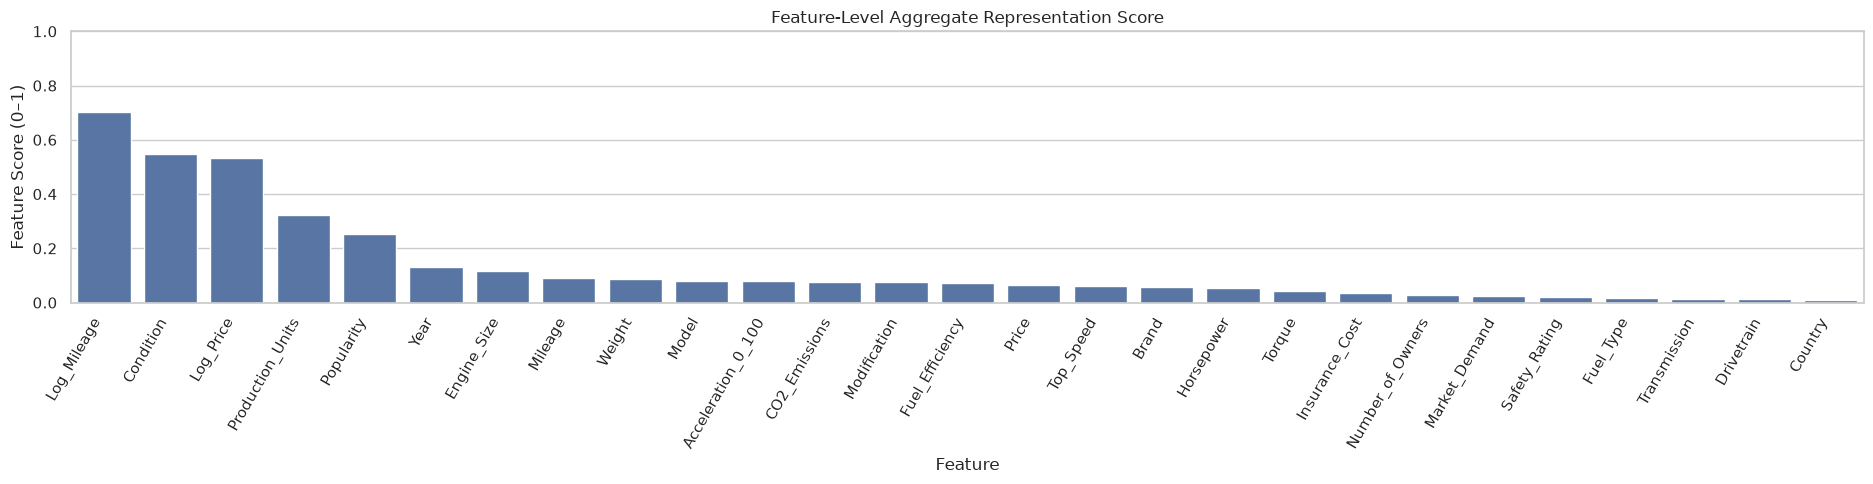

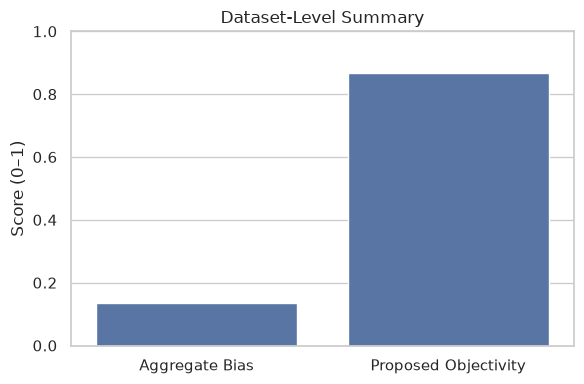

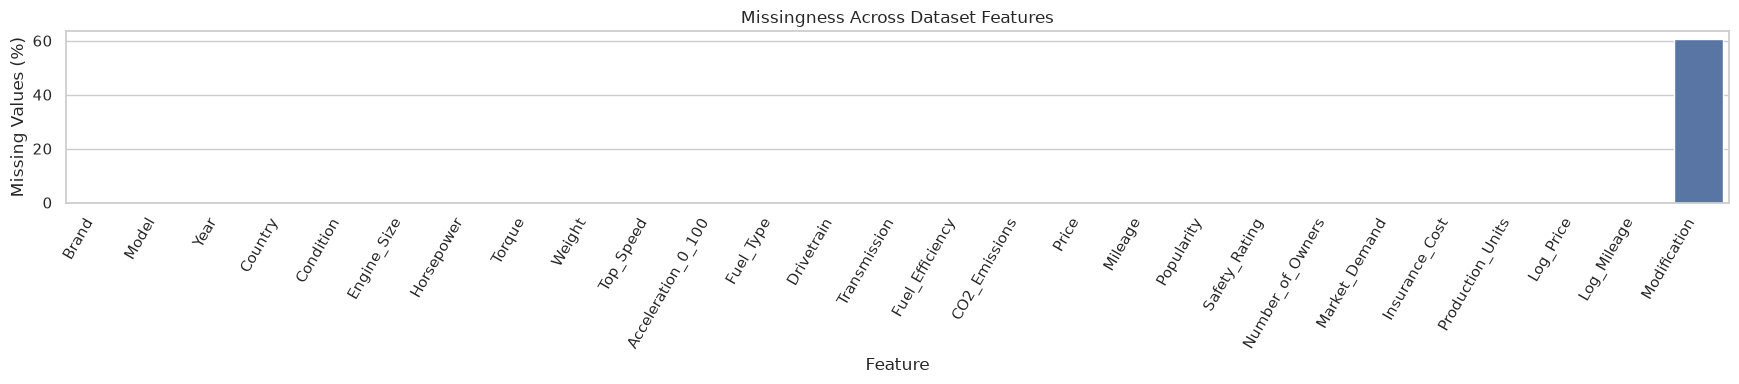

In [265]:
# 1. Compare NIS and JSD across features

if not feature_results.empty:

    metric_plot = feature_results.melt(
        id_vars="Feature",
        value_vars=["NIS", "JSD"],
        var_name="Metric",
        value_name="Score"
    )

    plt.figure(
        figsize=(max(9, len(feature_results) * 0.8), 5)
    )

    sns.barplot(
        data=metric_plot,
        x="Feature",
        y="Score",
        hue="Metric"
    )

    plt.title("Feature-Level Representation Indicators")
    plt.ylabel("Score (0–1)")
    plt.xlabel("Feature")
    plt.ylim(0, 1)

    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()


# 2. Feature-level aggregate score

if not feature_results.empty:

    ordered = feature_results.sort_values(
        "Feature Bias Score",
        ascending=False
    )

    plt.figure(
        figsize=(max(8, len(ordered) * 0.7), 5)
    )

    sns.barplot(
        data=ordered,
        x="Feature",
        y="Feature Bias Score"
    )

    plt.title("Feature-Level Aggregate Representation Score")
    plt.ylabel("Feature Score (0–1)")
    plt.xlabel("Feature")
    plt.ylim(0, 1)

    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()


# 3. Dataset-level bias and objectivity

if pd.notna(dataset_bias):

    plt.figure(figsize=(6, 4))

    sns.barplot(
        x=["Aggregate Bias", "Proposed Objectivity"],
        y=[dataset_bias, dataset_objectivity]
    )

    plt.title("Dataset-Level Summary")
    plt.ylabel("Score (0–1)")
    plt.ylim(0, 1)

    plt.tight_layout()
    plt.show()


# 4. Missingness overview

plt.figure(
    figsize=(max(8, len(feature_columns) * 0.65), 4)
)

sns.barplot(
    data=missing_summary,
    x="Feature",
    y="Missing %"
)

plt.title("Missingness Across Dataset Features")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=60, ha="right")

plt.tight_layout()
plt.show()

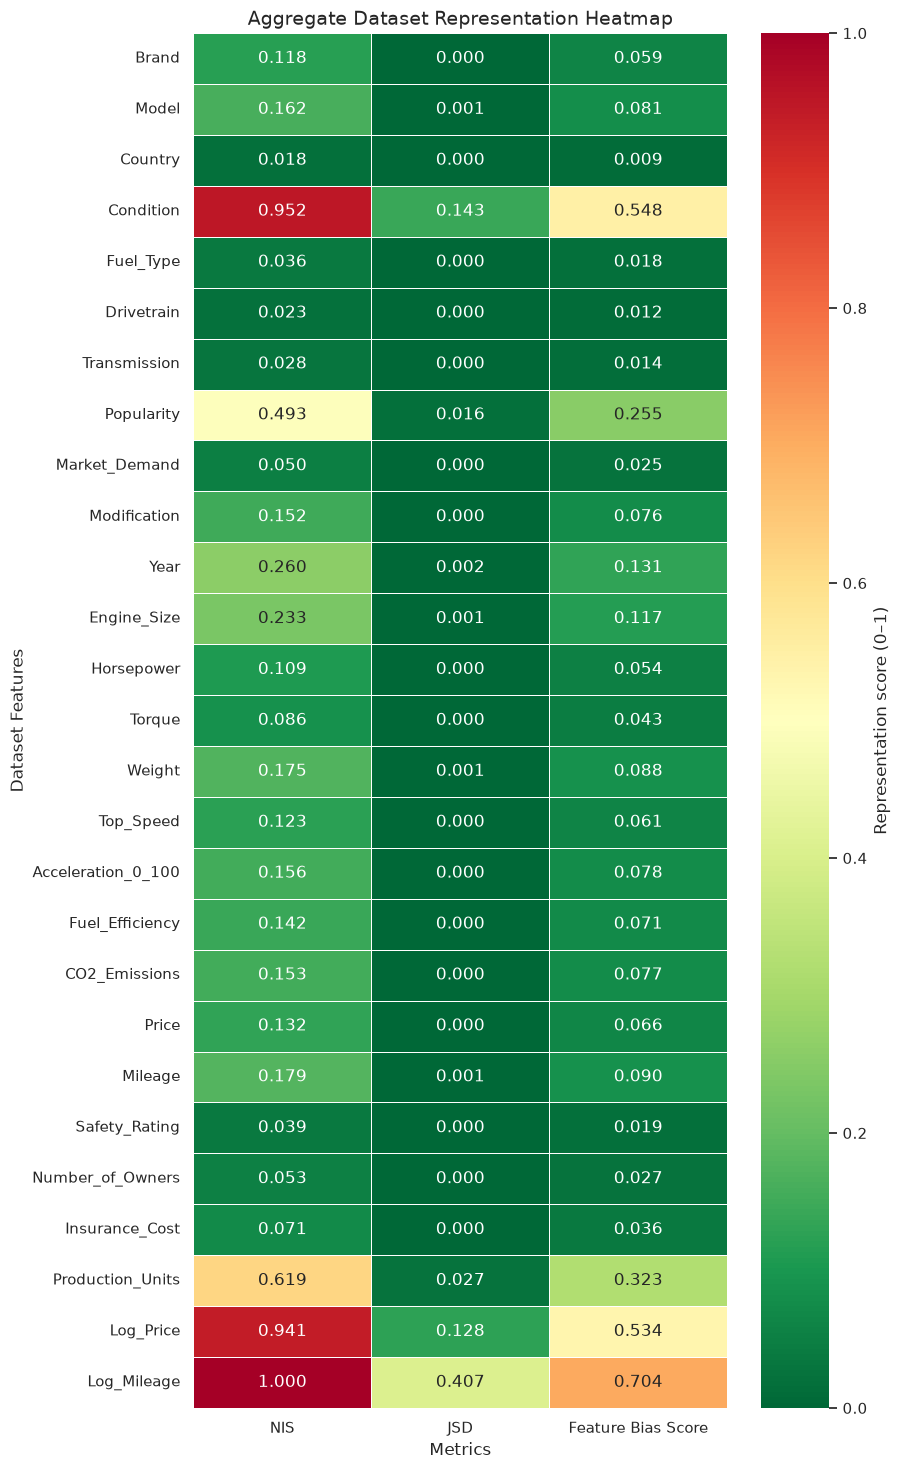

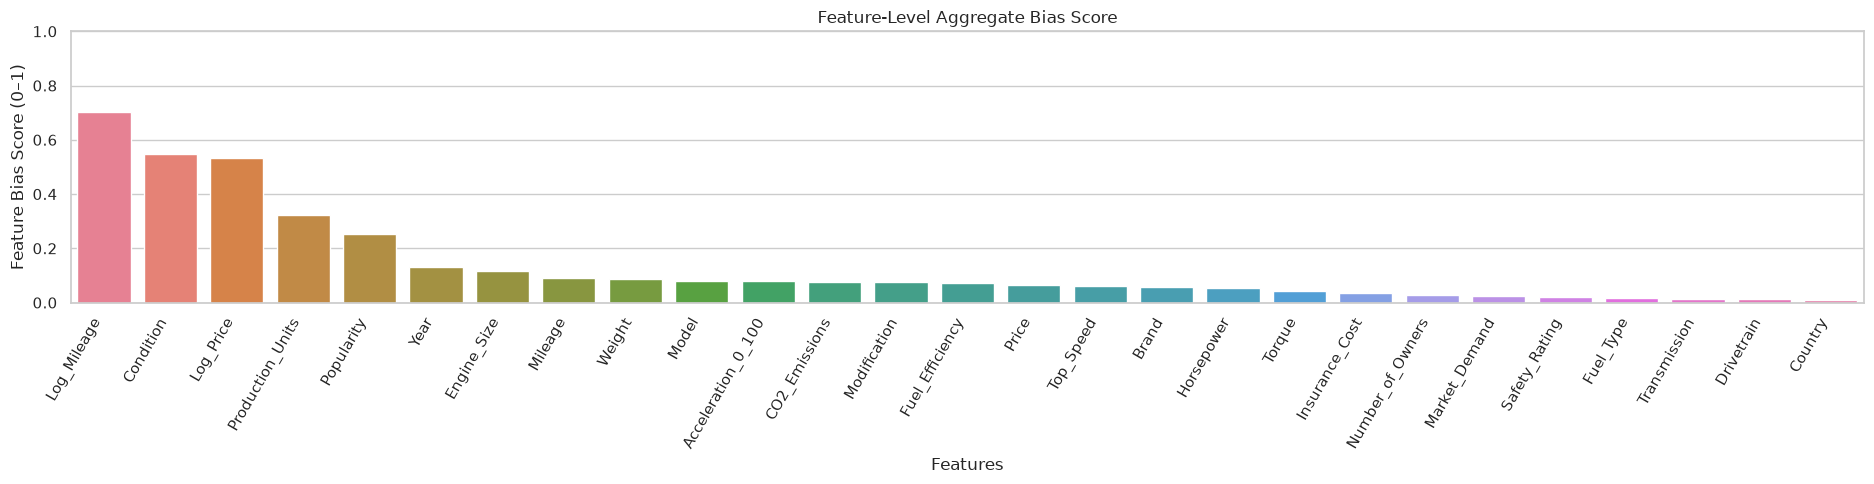

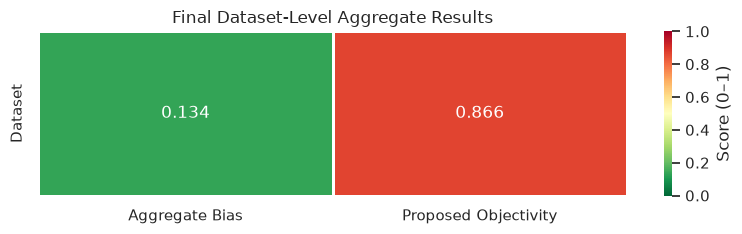

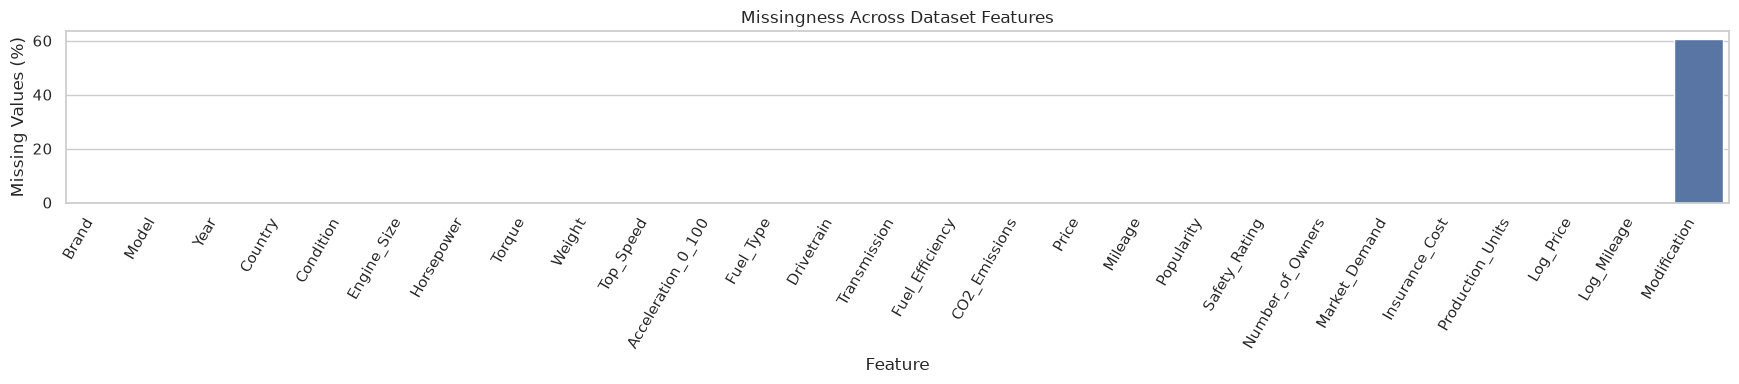

In [266]:
# ==========================================
# 1. AGGREGATE FEATURE-LEVEL HEATMAP
# ==========================================

if not feature_results.empty:

    heatmap_data = (
        feature_results
        .set_index("Feature")[
            ["NIS", "JSD", "Feature Bias Score"]
        ]
    )

    plt.figure(
        figsize=(
            9,
            max(4, len(heatmap_data) * 0.55)
        )
    )

    sns.heatmap(
        heatmap_data,
        annot=True,
        fmt=".3f",
        cmap="RdYlGn_r",
        vmin=0,
        vmax=1,
        linewidths=0.5,
        cbar_kws={
            "label": "Representation score (0–1)"
        }
    )

    plt.title(
        "Aggregate Dataset Representation Heatmap",
        fontsize=14
    )

    plt.xlabel("Metrics")
    plt.ylabel("Dataset Features")

    plt.tight_layout()
    plt.show()


# ==========================================
# 2. FEATURE-LEVEL AGGREGATE SCORE
# ==========================================

if not feature_results.empty:

    ordered = feature_results.sort_values(
        "Feature Bias Score",
        ascending=False
    )

    plt.figure(
        figsize=(
            max(8, len(ordered) * 0.7),
            5
        )
    )

    sns.barplot(
        data=ordered,
        x="Feature",
        y="Feature Bias Score",
        hue="Feature",
        legend=False
    )

    plt.title("Feature-Level Aggregate Bias Score")
    plt.ylabel("Feature Bias Score (0–1)")
    plt.xlabel("Features")
    plt.ylim(0, 1)

    plt.xticks(rotation=60, ha="right")
    plt.tight_layout()
    plt.show()


# ==========================================
# 3. DATASET-LEVEL FINAL SCORE HEATMAP
# ==========================================

if pd.notna(dataset_bias):

    dataset_heatmap = pd.DataFrame(
        [[dataset_bias, dataset_objectivity]],
        index=["Dataset"],
        columns=[
            "Aggregate Bias",
            "Proposed Objectivity"
        ]
    )

    plt.figure(figsize=(8, 2.5))

    sns.heatmap(
        dataset_heatmap,
        annot=True,
        fmt=".3f",
        cmap="RdYlGn_r",
        vmin=0,
        vmax=1,
        linewidths=1,
        cbar_kws={
            "label": "Score (0–1)"
        }
    )

    plt.title("Final Dataset-Level Aggregate Results")
    plt.tight_layout()
    plt.show()


# ==========================================
# 4. MISSINGNESS VISUALISATION
# ==========================================

plt.figure(
    figsize=(
        max(8, len(feature_columns) * 0.65),
        4
    )
)

sns.barplot(
    data=missing_summary,
    x="Feature",
    y="Missing %"
)

plt.title("Missingness Across Dataset Features")
plt.ylabel("Missing Values (%)")

plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()